In [1]:
import ee
import geemap
import pandas as pd
import numpy as np

In [2]:
ee.Authenticate(force=True)


Successfully saved authorization token.


In [3]:
ee.Initialize(project='carbonestimationversion2')

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


In [4]:
print(ee.String("Earth Engine Connected!").getInfo())

Earth Engine Connected!


In [5]:
import ee
import time

# 1. Study area
study_area = ee.Geometry.BBox(75.0, 18.0, 85.0, 28.0)

# 2. Load GEDI and Clean — stricter quality filtering
gedi = ee.ImageCollection('LARSE/GEDI/GEDI04_A_002_MONTHLY') \
         .filterBounds(study_area) \
         .filterDate('2022-01-01', '2023-12-31')

def filter_quality(img):
    quality_mask = img.select('l4_quality_flag').eq(1)
    degrade_mask = img.select('degrade_flag').eq(0)
    sensitivity_mask = img.select('sensitivity').gte(0.95)
    full_mask = quality_mask.And(degrade_mask).And(sensitivity_mask)
    return img.select('agbd').updateMask(full_mask)

gedi_clean = gedi.map(filter_quality).median().clip(study_area)

# 3. Stratify the Biomass into Classes — finer bins to give the tail real representation
# 1 (0-50), 2 (50-100), 3 (100-200), 4 (200-400), 5 (>400 Mg/ha)
agb_strata = ee.Image(1) \
    .where(gedi_clean.select('agbd').gt(50), 2) \
    .where(gedi_clean.select('agbd').gt(100), 3) \
    .where(gedi_clean.select('agbd').gt(200), 4) \
    .where(gedi_clean.select('agbd').gt(400), 5) \
    .toInt() \
    .rename('agb_class')

gedi_with_strata = gedi_clean.addBands(agb_strata)

# 4. Stratified Sampling
samples = gedi_with_strata.stratifiedSample(
    numPoints=6000,
    classBand='agb_class',
    region=study_area,
    scale=50,
    geometries=True,
    tileScale=16
)

print("Cell 1 Complete: Ground truth point collection (with strata) initiated.")
# NOTE: no .getInfo() diagnostic here — checking class balance interactively
# on a stratified sample with rare classes reliably times out. We'll check
# the actual per-class counts from the exported CSV instead (see Cell 5/7).

Cell 1 Complete: Ground truth point collection (with strata) initiated.


In [27]:
# 5. Optical (Sentinel-2) Processing with SAVI & MSAVI
def mask_s2_clouds(image):
    qa = image.select('QA60')
    cloud_bit_mask = 1 << 10
    cirrus_bit_mask = 1 << 11
    mask = qa.bitwiseAnd(cloud_bit_mask).eq(0).And(qa.bitwiseAnd(cirrus_bit_mask).eq(0))
    return image.updateMask(mask)

def add_indices(image):
    ndvi = image.normalizedDifference(['B8', 'B4']).rename('NDVI')
    evi = image.expression(
        '2.5 * ((NIR - RED) / (NIR + 6 * RED - 7.5 * BLUE + 10000))', {
            'NIR': image.select('B8'),
            'RED': image.select('B4'),
            'BLUE': image.select('B2')
        }).rename('EVI')

    savi = image.expression(
        '((NIR - RED) / (NIR + RED + 0.5)) * 1.5', {
            'NIR': image.select('B8'),
            'RED': image.select('B4')
        }).rename('SAVI')

    msavi = image.expression(
        '(2 * NIR + 1 - sqrt(pow((2 * NIR + 1), 2) - 8 * (NIR - RED))) / 2', {
            'NIR': image.select('B8'),
            'RED': image.select('B4')
        }).rename('MSAVI')

    return image.addBands([ndvi, evi, savi, msavi])

s2 = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED") \
    .filterBounds(study_area) \
    .filterDate('2022-01-01', '2023-12-31') \
    .map(mask_s2_clouds) \
    .map(add_indices) \
    .median() \
    .select(['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'EVI', 'SAVI', 'MSAVI'])

# 6. Radar (Sentinel-1) Processing & GLCM Texture
s1_col = ee.ImageCollection('COPERNICUS/S1_GRD') \
    .filterBounds(study_area) \
    .filterDate('2022-01-01', '2023-12-31') \
    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV')) \
    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH')) \
    .filter(ee.Filter.eq('instrumentMode', 'IW')) \
    .median() \
    .select(['VV', 'VH'])

# Convert VV and VH radar to positive integers and extract GLCM textures
s1_vv_int = s1_col.select('VV').multiply(100).add(3000).toInt()
s1_vh_int = s1_col.select('VH').multiply(100).add(3000).toInt()

glcm_vv = s1_vv_int.glcmTexture(size=3).select(['VV_contrast', 'VV_var', 'VV_ent'])
glcm_vh = s1_vh_int.glcmTexture(size=3).select(['VH_contrast', 'VH_var', 'VH_ent'])

# Derived SAR features for saturation mitigation
vh_vv_ratio = s1_col.select('VH').divide(s1_col.select('VV')).rename('VH_VV_ratio')
vh_vv_diff = s1_col.select('VH').subtract(s1_col.select('VV')).rename('VH_VV_diff')

s1 = s1_col.addBands([glcm_vv, glcm_vh, vh_vv_ratio, vh_vv_diff])

# ALOS PALSAR-2 (L-Band Radar) — calibrated to gamma-naught dB
# Raw DN values need conversion: gamma0(dB) = 10*log10(DN^2) - 83.0
palsar_dn = ee.ImageCollection('JAXA/ALOS/PALSAR/YEARLY/SAR_EPOCH') \
    .filterBounds(study_area) \
    .filterDate('2022-01-01', '2023-12-31') \
    .mosaic() \
    .select(['HH', 'HV'])

def dn_to_gamma0(img):
    return img.pow(2).log10().multiply(10).subtract(83.0)

palsar = dn_to_gamma0(palsar_dn).rename(['PALSAR_HH', 'PALSAR_HV'])

# 7. Topography & Canopy Height
srtm = ee.Image('USGS/SRTMGL1_003')
elevation = srtm.select('elevation')
slope = ee.Terrain.slope(elevation).rename('slope')
aspect = ee.Terrain.aspect(elevation).rename('aspect')

canopy_height = ee.Image("users/nlang/ETH_GlobalCanopyHeight_2020_10m_v1").rename('canopy_height')
lon_lat = ee.Image.pixelLonLat()

# Land type 
worldcover = ee.ImageCollection("ESA/WorldCover/v200").first().select('Map').rename('LandCover')

# 9. Stack Features & Sample
stacked_features = s2 \
    .addBands(s1) \
    .addBands(palsar) \
    .addBands(elevation) \
    .addBands(slope) \
    .addBands(aspect) \
    .addBands(canopy_height) \
    .addBands(worldcover) \
    .addBands(lon_lat)

training_data = stacked_features.sampleRegions(
    collection=samples,
    properties=['agbd', 'agb_class'],
    scale=30,
    tileScale=16
)

# 10. Start Export Task
export_task = ee.batch.Export.table.toDrive(
    collection=training_data,
    description='Biomass_Enhanced_Features_2022_2023_v2',
    folder='EarthEngine_ML_Project',
    fileFormat='CSV'
)
export_task.start()

print("Export task started successfully! Monitoring progress...")

# 11. Active Task Monitoring Loop
status = export_task.status()
while status['state'] in ['READY', 'RUNNING']:
    print(f"Status: {status['state']}... checking again in 15 seconds.")
    time.sleep(15)
    status = export_task.status()

if status['state'] == 'COMPLETED':
    print("\nTask complete! The enhanced CSV file has been written to your Google Drive.")
else:
    print(f"\nTask failed with error: {status.get('error_message')}")

Export task started successfully! Monitoring progress...
Status: READY... checking again in 15 seconds.
Status: RUNNING... checking again in 15 seconds.
Status: RUNNING... checking again in 15 seconds.
Status: RUNNING... checking again in 15 seconds.
Status: RUNNING... checking again in 15 seconds.
Status: RUNNING... checking again in 15 seconds.
Status: RUNNING... checking again in 15 seconds.
Status: RUNNING... checking again in 15 seconds.
Status: RUNNING... checking again in 15 seconds.
Status: RUNNING... checking again in 15 seconds.
Status: RUNNING... checking again in 15 seconds.
Status: RUNNING... checking again in 15 seconds.
Status: RUNNING... checking again in 15 seconds.
Status: RUNNING... checking again in 15 seconds.
Status: RUNNING... checking again in 15 seconds.
Status: RUNNING... checking again in 15 seconds.
Status: RUNNING... checking again in 15 seconds.
Status: RUNNING... checking again in 15 seconds.
Status: RUNNING... checking again in 15 seconds.
Status: RUNNIN

### Let's Import the final dataset 

In [7]:
df = pd.read_csv('Biomass_Enhanced_Features_2022_2023_v2(1).csv')
print(df.shape)
df.info()
df.head()
df.shape

(25634, 33)
<class 'pandas.DataFrame'>
RangeIndex: 25634 entries, 0 to 25633
Data columns (total 33 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   system:index   25634 non-null  str    
 1   B11            25634 non-null  float64
 2   B12            25634 non-null  float64
 3   B2             25634 non-null  float64
 4   B3             25634 non-null  float64
 5   B4             25634 non-null  float64
 6   B8             25634 non-null  float64
 7   EVI            25634 non-null  float64
 8   LandCover      25634 non-null  int64  
 9   MSAVI          25634 non-null  float64
 10  NDVI           25634 non-null  float64
 11  PALSAR_HH      25634 non-null  float64
 12  PALSAR_HV      25634 non-null  float64
 13  SAVI           25634 non-null  float64
 14  VH             25634 non-null  float64
 15  VH_VV_diff     25634 non-null  float64
 16  VH_VV_ratio    25634 non-null  float64
 17  VH_contrast    25634 non-null  float64
 18  VH_en

(25634, 33)

In [8]:
print(df['LandCover'].value_counts())

LandCover
10    17574
40     5171
30     2429
20      341
50       68
60       39
80       10
90        2
Name: count, dtype: int64


In [9]:
print(df['agb_class'].value_counts().sort_index())

agb_class
1    5950
2    5976
3    5969
4    5883
5    1856
Name: count, dtype: int64


### Dropping the useless columns that were used for data extraction only

In [10]:
columns_to_drop = ['system:index' ,'.geo']
df = df.drop(columns = columns_to_drop, errors = 'ignore')
print(df.shape)
df.sample(3)

(25634, 31)


,B11,B12,B2,B3,B4,B8,EVI,LandCover,MSAVI,NDVI,...,VV_ent,VV_var,agb_class,agbd,aspect,canopy_height,elevation,latitude,longitude,slope
10455,2423.00,1593.000000,568.928571,862.285714,833.538462,2855.750000,0.348827,10,0.638490,0.469003,...,4.349616,25310.467430,2,62.615635,207.98056,13,608,19.757322,81.763983,4.193532
6202,2313.80,1520.777778,557.536585,819.785714,827.642857,2661.125000,0.284837,10,0.585246,0.417589,...,4.353741,10129.589175,2,67.070389,130.98297,21,385,20.675759,84.902787,17.790144
11128,2145.08,1331.769231,448.847059,820.129032,698.647059,2785.333333,0.347761,10,0.722019,0.558289,...,4.345490,4647.353422,2,89.627617,270.00000,18,753,23.505452,82.086568,1.011312


In [11]:
print(df.isnull().sum())

B11              0
B12              0
B2               0
B3               0
B4               0
B8               0
EVI              0
LandCover        0
MSAVI            0
NDVI             0
PALSAR_HH        0
PALSAR_HV        0
SAVI             0
VH               0
VH_VV_diff       0
VH_VV_ratio      0
VH_contrast      0
VH_ent           0
VH_var           0
VV               0
VV_contrast      0
VV_ent           0
VV_var           0
agb_class        0
agbd             0
aspect           0
canopy_height    0
elevation        0
latitude         0
longitude        0
slope            0
dtype: int64


### X and Y splitting

In [12]:
y = df['agbd']
X = df.drop(columns=['agbd', 'agb_class'])
agb_class_full = df['agb_class']


In [13]:
X = pd.get_dummies(X, columns = ['LandCover'], prefix = 'lc')
print('y_shape' , y.shape)
print('X_shape' , X.shape)
print(X.columns.tolist())

y_shape (25634,)
X_shape (25634, 36)
['B11', 'B12', 'B2', 'B3', 'B4', 'B8', 'EVI', 'MSAVI', 'NDVI', 'PALSAR_HH', 'PALSAR_HV', 'SAVI', 'VH', 'VH_VV_diff', 'VH_VV_ratio', 'VH_contrast', 'VH_ent', 'VH_var', 'VV', 'VV_contrast', 'VV_ent', 'VV_var', 'aspect', 'canopy_height', 'elevation', 'latitude', 'longitude', 'slope', 'lc_10', 'lc_20', 'lc_30', 'lc_40', 'lc_50', 'lc_60', 'lc_80', 'lc_90']


### Train test split

In [14]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


c:\Users\kr070\Desktop\Carbon_stock\.venv\Scripts\python.exe: No module named pip


In [15]:
from sklearn.model_selection import train_test_split
X_train , X_test , y_train, y_test, agb_class_train, agb_class_test = train_test_split(
    X,y,agb_class_full,
    test_size = 0.2,
    random_state = 42
)
print('X_train_shape :', X_train.shape,
      'X_test_shape', X_test.shape,
      'y_train_shape', y_train.shape,
      'y_test_shape', y_test.shape)

X_train_shape : (20507, 36) X_test_shape (5127, 36) y_train_shape (20507,) y_test_shape (5127,)


In [16]:
y_train.describe()

count    20507.000000
mean       152.763416
std        168.975494
min          0.787927
25%         52.739626
50%        107.914368
75%        215.983246
max       3179.001953
Name: agbd, dtype: float64

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [18]:
y_train

20551    235.402802
15652    105.778252
22376    280.375702
20038    200.592850
4824      14.292865
            ...    
21575    226.470840
5390      10.193696
860       13.853773
15795    130.761017
23654    240.123520
Name: agbd, Length: 20507, dtype: float64

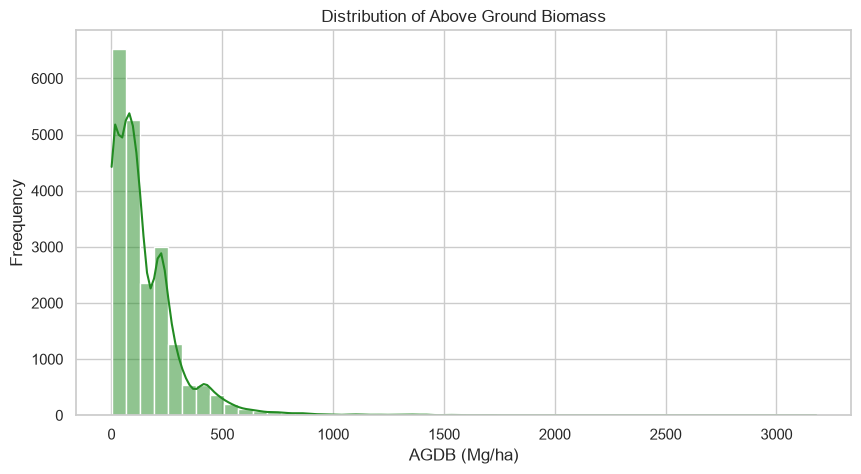

In [19]:
plt.figure(figsize = (10,5))
sns.histplot(y_train , bins = 50, kde=True, color = 'forestgreen')
plt.title('Distribution of Above Ground Biomass')
plt.xlabel('AGDB (Mg/ha)')
plt.ylabel('Freequency')
plt.show()

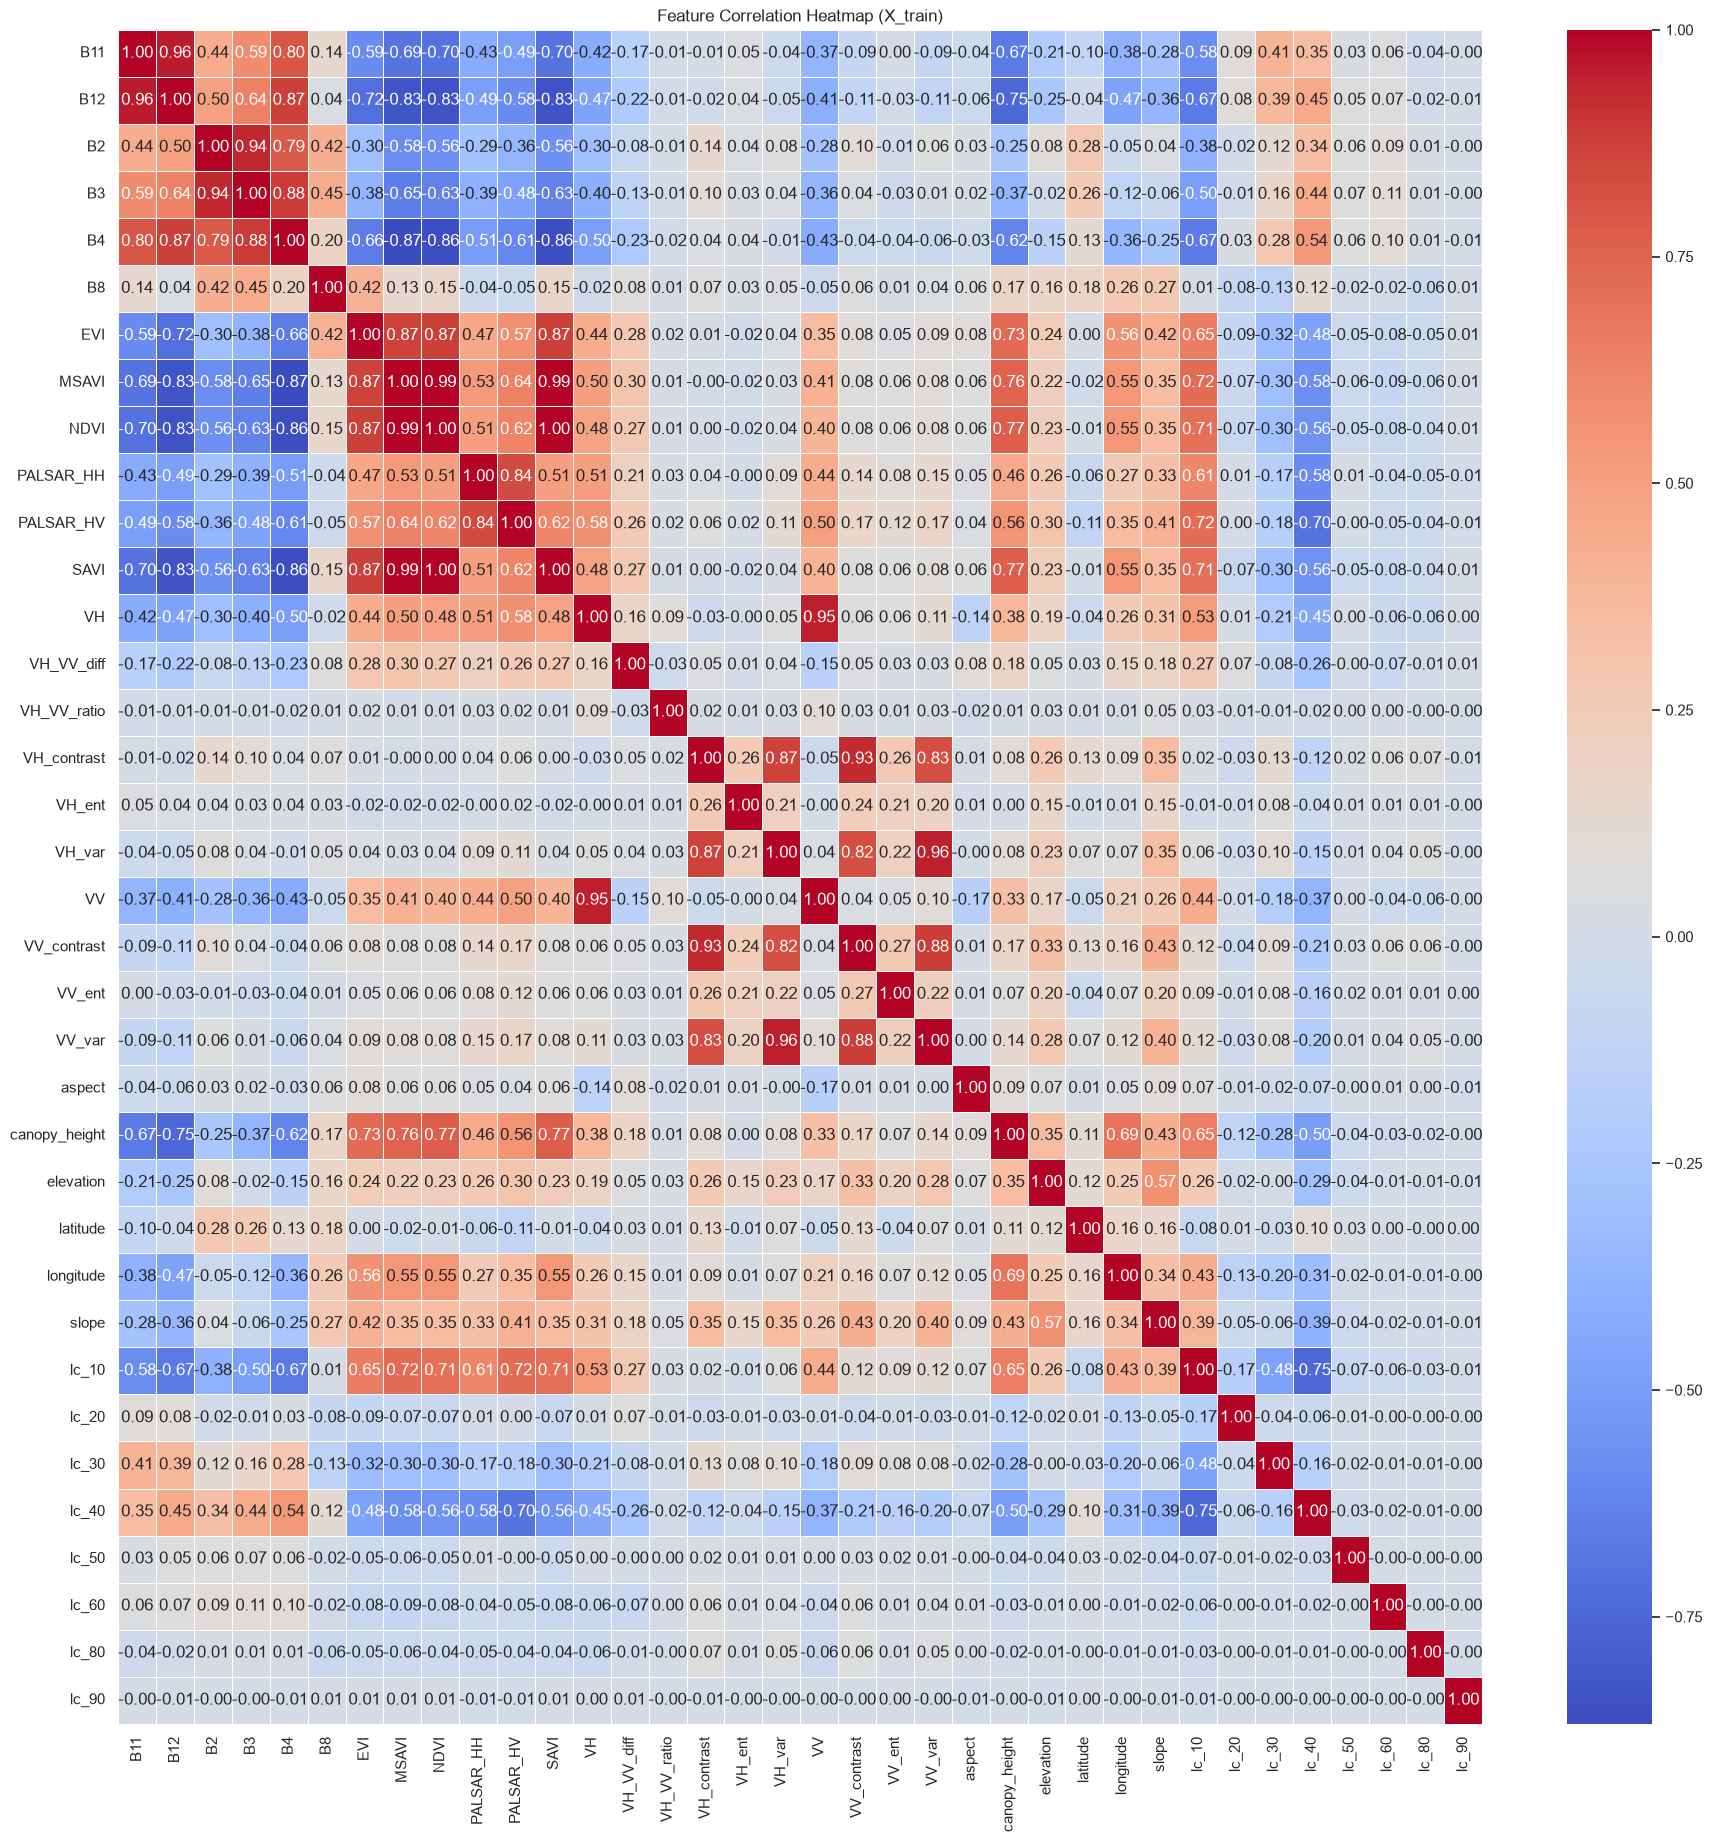

In [20]:
plt.figure(figsize=(22,22))

correlation_matrix = X_train.corr()

sns.heatmap(
    correlation_matrix,
    annot = True,
    cmap = 'coolwarm',
    fmt = '.2f',
    linewidths = 0.5,
)

plt.title("Feature Correlation Heatmap (X_train)")
plt.show()


### Feature vs. Target Scatter Plot

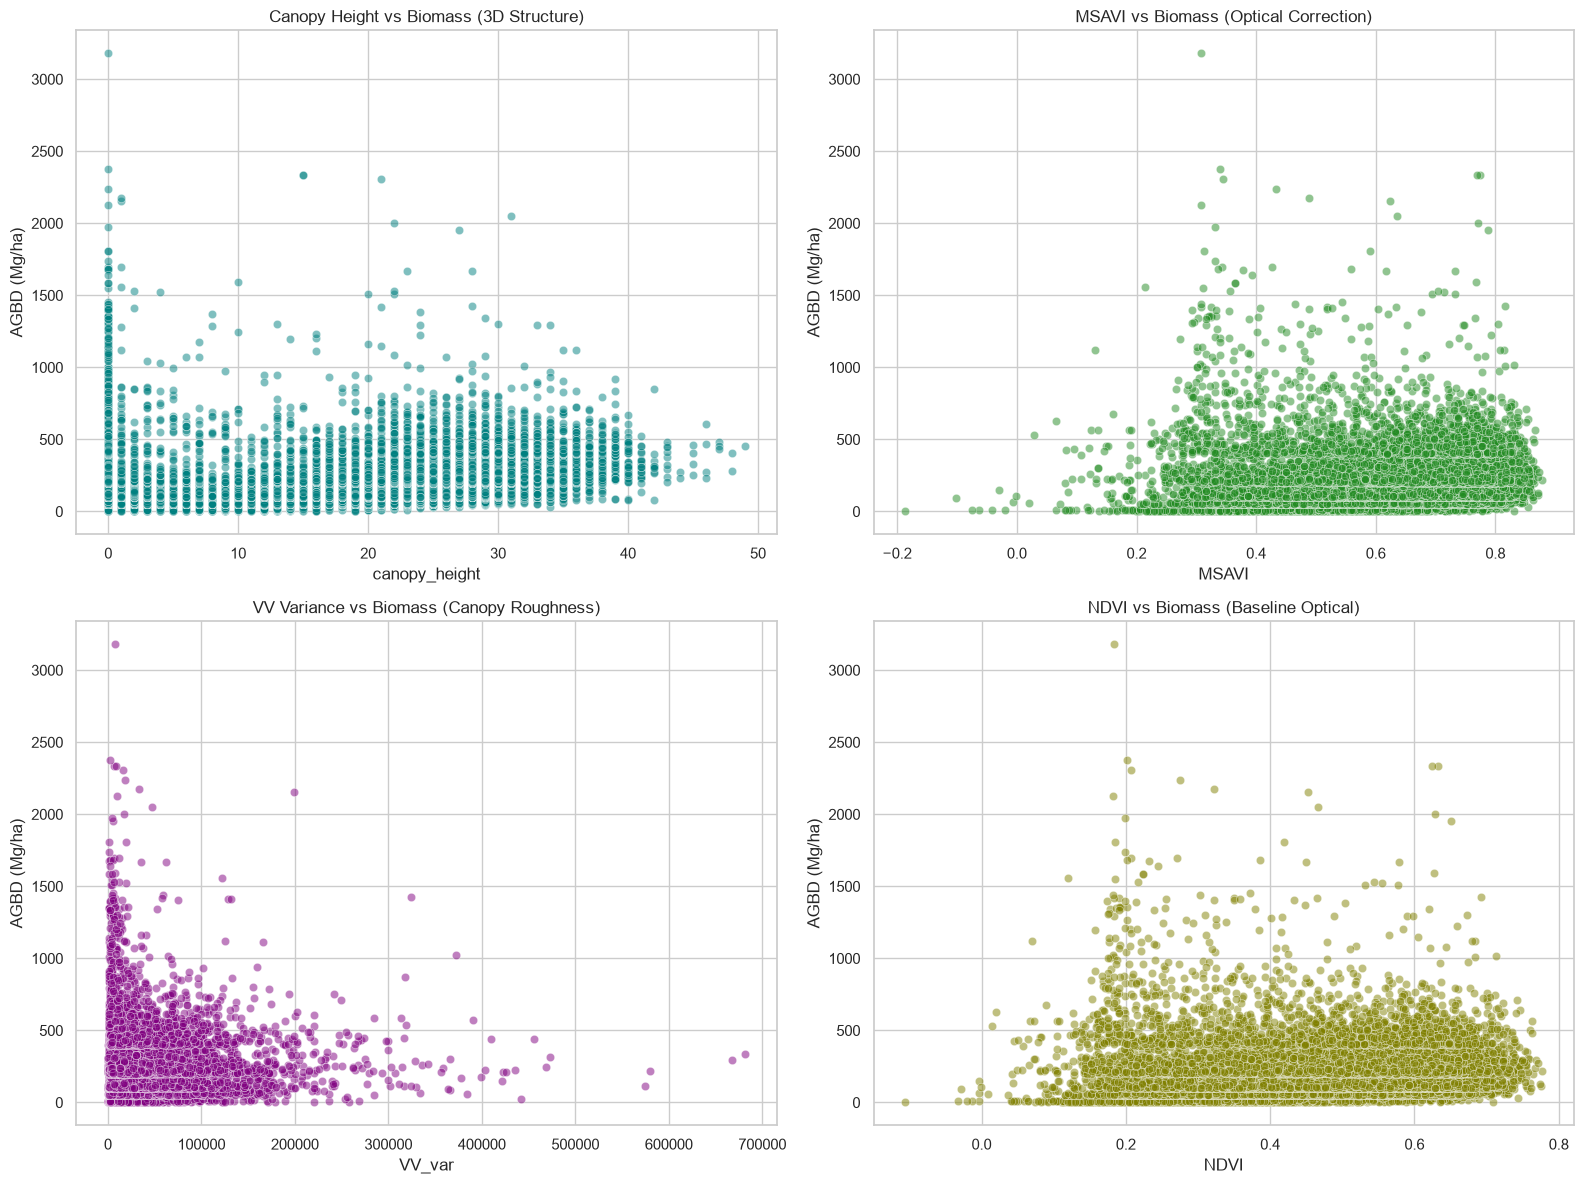

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. 3D Structure: Canopy Height vs AGBD
sns.scatterplot(x=df['canopy_height'], y=df['agbd'], ax=axes[0, 0], alpha=0.5, color='teal')
axes[0, 0].set_title('Canopy Height vs Biomass (3D Structure)')
axes[0, 0].set_ylabel('AGBD (Mg/ha)')

# 2. Soil-Adjusted Index: MSAVI vs AGBD
sns.scatterplot(x=df['MSAVI'], y=df['agbd'], ax=axes[0, 1], alpha=0.5, color='forestgreen')
axes[0, 1].set_title('MSAVI vs Biomass (Optical Correction)')
axes[0, 1].set_ylabel('AGBD (Mg/ha)')

# 3. Radar Texture: VV Variance vs AGBD
sns.scatterplot(x=df['VV_var'], y=df['agbd'], ax=axes[1, 0], alpha=0.5, color='purple')
axes[1, 0].set_title('VV Variance vs Biomass (Canopy Roughness)')
axes[1, 0].set_ylabel('AGBD (Mg/ha)')

# 4. Baseline Comparison: NDVI vs AGBD
sns.scatterplot(x=df['NDVI'], y=df['agbd'], ax=axes[1, 1], alpha=0.5, color='olive')
axes[1, 1].set_title('NDVI vs Biomass (Baseline Optical)')
axes[1, 1].set_ylabel('AGBD (Mg/ha)')

plt.tight_layout()
plt.show()


### Fixing Multicolinearity 

In [22]:
print("X_train_shape : ", X_train.shape)
print("X_test_shape : ", X_test.shape)

X_train_shape :  (20507, 36)
X_test_shape :  (5127, 36)


In [23]:
columns_to_drop = ['B2' ,'B3', 'B11', 'NDVI', 'SAVI', 'VV', 'VV_contrast','VH_var',  'latitude' , 'longitude']
X_train = X_train.drop(columns=columns_to_drop, errors='ignore')
X_test = X_test.drop(columns=columns_to_drop, errors='ignore')

print(list(X_train.columns))
print("X_train_shape : ", X_train.shape)
print("X_test_shape : ", X_test.shape)

['B12', 'B4', 'B8', 'EVI', 'MSAVI', 'PALSAR_HH', 'PALSAR_HV', 'VH', 'VH_VV_diff', 'VH_VV_ratio', 'VH_contrast', 'VH_ent', 'VV_ent', 'VV_var', 'aspect', 'canopy_height', 'elevation', 'slope', 'lc_10', 'lc_20', 'lc_30', 'lc_40', 'lc_50', 'lc_60', 'lc_80', 'lc_90']
X_train_shape :  (20507, 26)
X_test_shape :  (5127, 26)


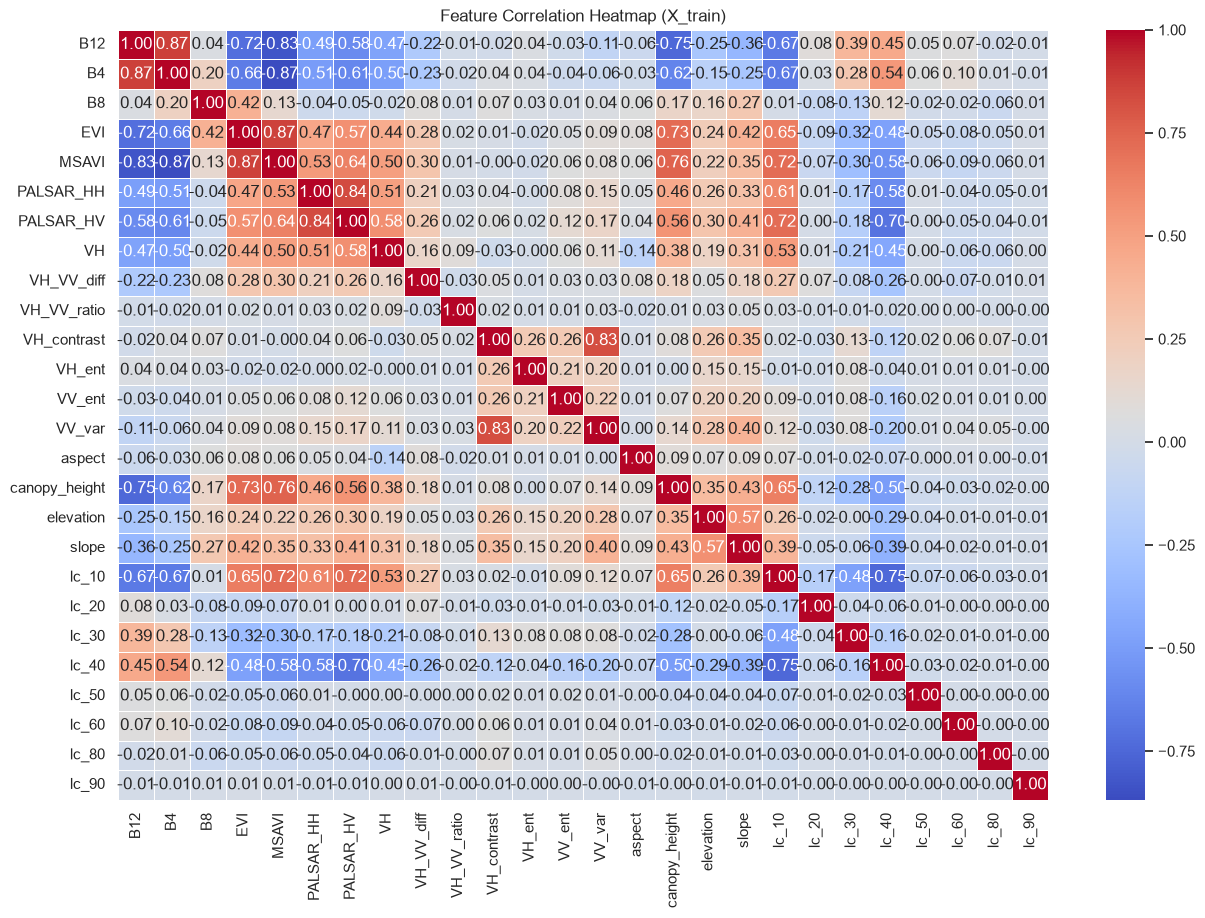

In [24]:
plt.figure(figsize=(15,10))

correlation_matrix = X_train.corr()

sns.heatmap(
    correlation_matrix,
    annot = True,
    cmap = 'coolwarm',
    fmt = '.2f',
    linewidths = 0.5,
)

plt.title("Feature Correlation Heatmap (X_train)")
plt.show()


### Eliminating Threshold
There are 4 outlier points in both training and testing data

In [25]:
# Fixing the training Data 


cond_no_outliers_train = y_train <= 400
cond_no_anomalies_train = ~((X_train['canopy_height'] == 0) & (y_train > 50))

valid_indices_train = y_train[cond_no_outliers_train & cond_no_anomalies_train].index

X_train = X_train.loc[valid_indices_train]
y_train = y_train.loc[valid_indices_train]
agb_class_train = agb_class_train.loc[valid_indices_train]

# Fixing the testing data 
cond_no_outliers_test = y_test <= 400
cond_no_anomalies_test = ~((X_test['canopy_height'] == 0) & (y_test > 50))

valid_indices_test = y_test[cond_no_outliers_test & cond_no_anomalies_test].index

X_test = X_test.loc[valid_indices_test]
y_test = y_test.loc[valid_indices_test]
agb_class_test = agb_class_test.loc[valid_indices_test]

print("X_train_shape :", X_train.shape)
print("y_train_shape :", y_train.shape)
print("X_test_shape :", X_test.shape)
print("y_test_shape :", y_test.shape)
print("agb_class_train_shape :", agb_class_train.shape)
print("agb_class_test_shape :", agb_class_test.shape)

X_train_shape : (16234, 26)
y_train_shape : (16234,)
X_test_shape : (4023, 26)
y_test_shape : (4023,)
agb_class_train_shape : (16234,)
agb_class_test_shape : (4023,)


### Log Trnasformation on target 

Y_train_transformed shape : (16234,)


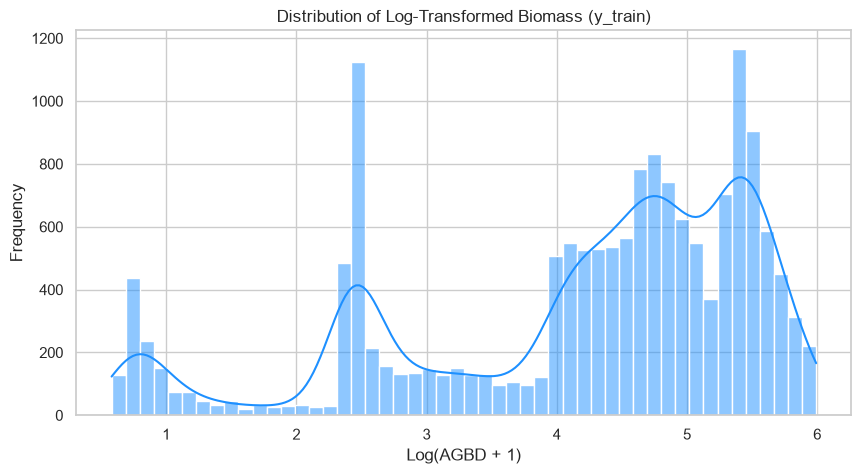

In [26]:
y_train_transformed = np.log1p(y_train)
print("Y_train_transformed shape :" , y_train_transformed.shape)
plt.figure(figsize=(10, 5))
sns.histplot(y_train_transformed, bins=50, kde=True, color='dodgerblue')
plt.title("Distribution of Log-Transformed Biomass (y_train)")
plt.xlabel("Log(AGBD + 1)")
plt.ylabel("Frequency")
plt.show()

In [27]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_squared_error , mean_absolute_error , r2_score
import xgboost as xgb


In [28]:
param_grid = {
    'n_estimators' : [50,100,200,300],
    'learning_rate' : [0.01,0.05,0.1,0.2],
    'max_depth' : [3,5,7,10],
    'subsample' : [0.7,0.8,0.9,1.0],        #Fraction of data use per tree
    'colsample_bytree' : [0.7,0.8,0.9,1],     #Fractions of features used per tree
    'colsample_bylevel': [0.5, 0.7, 0.9, 1.0]
}

In [29]:
xgb = xgb.XGBRegressor(random_state = 42)

In [30]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import make_scorer

skf = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)
cv_splits = list(skf.split(X_train, agb_class_train))

random_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_grid,
    n_iter=75,          # Tests 25 random combinations
    scoring='neg_mean_squared_error',
    cv=cv_splits,            
    verbose=1,
    random_state=42,
    n_jobs=-1           # Uses all available CPU cores to speed it up
)

In [31]:
random_search.fit(X_train, y_train_transformed)

Fitting 5 folds for each of 75 candidates, totalling 375 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bylevel': [0.5, 0.7, ...], 'colsample_bytree': [0.7, 0.8, ...], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",75
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 1,...hape=(12987,)), ...), (array([ 0,...hape=(12987,)), ...), ...]"
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are consid

In [32]:
best_xgb_model = random_search.best_estimator_

In [33]:
X_train.columns

Index(['B12', 'B4', 'B8', 'EVI', 'MSAVI', 'PALSAR_HH', 'PALSAR_HV', 'VH',
       'VH_VV_diff', 'VH_VV_ratio', 'VH_contrast', 'VH_ent', 'VV_ent',
       'VV_var', 'aspect', 'canopy_height', 'elevation', 'slope', 'lc_10',
       'lc_20', 'lc_30', 'lc_40', 'lc_50', 'lc_60', 'lc_80', 'lc_90'],
      dtype='str')

In [34]:
best_xgb_model.feature_importances_

array([4.4226563e-03, 1.7918104e-03, 1.7881511e-03, 1.5940689e-02,
       8.6506894e-03, 3.2058582e-03, 7.2719553e-03, 2.2716664e-03,
       1.8282994e-03, 1.6004477e-03, 2.8502028e-03, 1.2963018e-03,
       1.2614051e-03, 3.8751387e-03, 1.3917601e-03, 5.8609083e-02,
       4.6435879e-03, 5.5321003e-03, 8.2914925e-01, 1.4440387e-03,
       1.7437855e-03, 3.5791077e-02, 1.1966588e-03, 1.6658582e-03,
       7.7756494e-04, 0.0000000e+00], dtype=float32)

In [35]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# For Training data 

y_train_pred_log = best_xgb_model.predict(X_train)

# Convert predictions back to real-world Mg/ha
y_train_pred = np.expm1(y_train_pred_log)

# Calculate metrics against the ORIGINAL y_train (which is in real Mg/ha)
r2_train = r2_score(y_train, y_train_pred)
mse_train = mean_squared_error(y_train, y_train_pred)
rmse_train = np.sqrt(mse_train)
mae_train = mean_absolute_error(y_train, y_train_pred)

print("--- Optimized Model Evaluation on Training Set ---")
print(f"R² Score: {r2_train:.4f}")
print(f"MSE:      {mse_train:.2f}")
print(f"RMSE:     {rmse_train:.2f} Mg/ha")
print(f"MAE:      {mae_train:.2f} Mg/ha")


#For testing data 

y_pred_log_opt = best_xgb_model.predict(X_test)

# Convert predictions back to real-world Mg/ha
y_pred_opt = np.expm1(y_pred_log_opt)

# Calculate metrics against y_test (which is already in real Mg/ha)
r2_opt = r2_score(y_test, y_pred_opt)
mse_opt = mean_squared_error(y_test, y_pred_opt)
rmse_opt = np.sqrt(mse_opt)
mae_opt = mean_absolute_error(y_test, y_pred_opt)

print("\n--- Optimized Model Evaluation on Test Set ---")
print(f"R² Score: {r2_opt:.4f}")
print(f"MSE:      {mse_opt:.2f}")
print(f"RMSE:     {rmse_opt:.2f} Mg/ha")
print(f"MAE:      {mae_opt:.2f} Mg/ha")

--- Optimized Model Evaluation on Training Set ---
R² Score: 0.6656
MSE:      3174.35
RMSE:     56.34 Mg/ha
MAE:      37.57 Mg/ha

--- Optimized Model Evaluation on Test Set ---
R² Score: 0.6139
MSE:      3655.84
RMSE:     60.46 Mg/ha
MAE:      41.04 Mg/ha


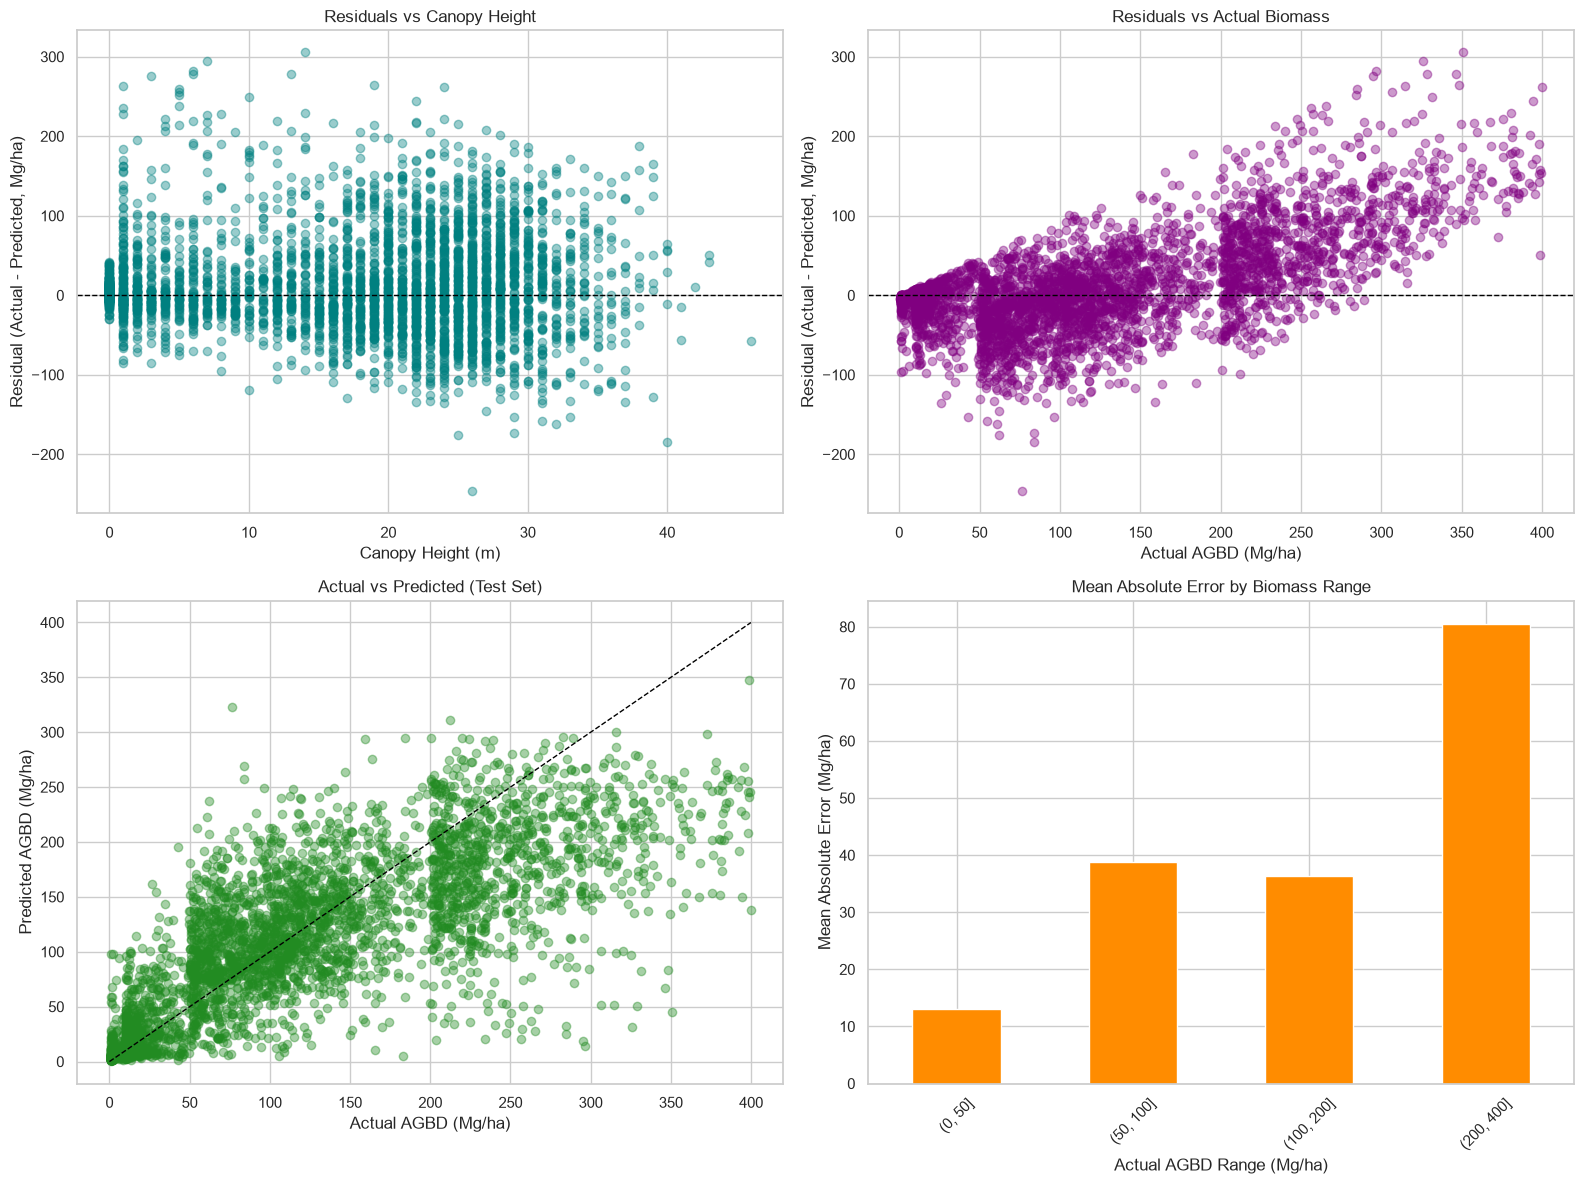

Residual stats by biomass range:
                 mean        std  count
bin                                    
(0, 50]     -7.367532  21.144191   1199
(50, 100]  -25.803439  43.540740    857
(100, 200]   2.827177  46.850225    956
(200, 400]  74.200520  64.817027   1011


In [36]:
# Residuals: actual - predicted (positive = model underestimated, negative = overestimated)
residuals = y_test.values - y_pred_opt

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Residuals vs canopy_height — checks for selection-bias / canopy-complexity effect
axes[0, 0].scatter(X_test['canopy_height'], residuals, alpha=0.4, color='teal')
axes[0, 0].axhline(0, color='black', linestyle='--', linewidth=1)
axes[0, 0].set_xlabel('Canopy Height (m)')
axes[0, 0].set_ylabel('Residual (Actual - Predicted, Mg/ha)')
axes[0, 0].set_title('Residuals vs Canopy Height')

# 2. Residuals vs actual biomass — checks for tail/outlier-cap effect
axes[0, 1].scatter(y_test, residuals, alpha=0.4, color='purple')
axes[0, 1].axhline(0, color='black', linestyle='--', linewidth=1)
axes[0, 1].set_xlabel('Actual AGBD (Mg/ha)')
axes[0, 1].set_ylabel('Residual (Actual - Predicted, Mg/ha)')
axes[0, 1].set_title('Residuals vs Actual Biomass')

# 3. Actual vs Predicted scatter — the classic diagnostic, should hug the y=x line
max_val = max(y_test.max(), y_pred_opt.max())
axes[1, 0].scatter(y_test, y_pred_opt, alpha=0.4, color='forestgreen')
axes[1, 0].plot([0, max_val], [0, max_val], color='black', linestyle='--', linewidth=1)
axes[1, 0].set_xlabel('Actual AGBD (Mg/ha)')
axes[1, 0].set_ylabel('Predicted AGBD (Mg/ha)')
axes[1, 0].set_title('Actual vs Predicted (Test Set)')

# 4. Absolute error vs actual biomass, binned — clearest view of where error concentrates
bins = pd.cut(y_test, bins=[0, 50, 100, 200, 400, 1000])
abs_error_by_bin = pd.Series(np.abs(residuals), index=y_test.index).groupby(bins, observed=True).mean()
abs_error_by_bin.plot(kind='bar', ax=axes[1, 1], color='darkorange')
axes[1, 1].set_xlabel('Actual AGBD Range (Mg/ha)')
axes[1, 1].set_ylabel('Mean Absolute Error (Mg/ha)')
axes[1, 1].set_title('Mean Absolute Error by Biomass Range')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Quick numeric summary alongside the plots
print("Residual stats by biomass range:")
print(pd.DataFrame({'residual': residuals, 'actual': y_test.values}).assign(
    bin=pd.cut(y_test.values, bins=[0, 50, 100, 200, 400, 1000])
).groupby('bin', observed=True)['residual'].agg(['mean', 'std', 'count']))

### Saving the model

In [37]:
import joblib, json
joblib.dump(best_xgb_model, 'biomass_model.joblib')
json.dump(list(X_train.columns), open('feature_columns.json', 'w'))